# Week 40, Monday lecture: from logistic regression to our first neural network

**FYS-STK3155/4155, Monday September 28, 2026**

This notebook contains the code behind every figure and number in the Monday
slides (`week40slides.pdf`). It follows the lecture: a reminder of logistic
regression as a single neuron and of the two sweeps of automatic
differentiation (Section 5.8 of the lecture notes), an introduction to neural
networks (Sections 8.1–8.7: the neuron, XOR, multilayer perceptrons, the
universal approximation theorem, activation functions, the cost), and
backpropagation from the smallest networks (Sections 8.8.1–8.8.2: no hidden
layer, one hidden layer, and the 2–2–1 network), by hand and with `jax.grad`.
The functions are the ones in `make_week40_figures.py`; the seeds are those
of the book (0 for the scalar training program, 41 for the 2–2–1 network) and
2026 for XOR, so that the figures here are the figures on the slides.

There are no weekly exercises this week: Project 1 is due Monday October 5.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

BLUE, RED, YELLOW, GREY = "#004488", "#BB5566", "#DDAA33", "#777777"
GREEN = "#228833"
np.set_printoptions(precision=4, suppress=True)

## Part 1: the reminder — one neuron, read forwards and backwards (Section 5.8)

Logistic regression drawn as a diagram is a single artificial neuron: the
features enter on the left, every edge carries a parameter, the intercept is
the weight of an input fixed at one, $\Sigma$ forms the linear predictor $z$
and $\sigma$ turns it into the probability (book Figure 5.4). The cost of one
observation depends on the parameters only through $z$, so by the chain rule,
Eq. (5.36),

$$
\frac{\partial C_i}{\partial\theta_j}=(\hat p_i-y_i)\,x_{ij},
\qquad
\theta_j\leftarrow\theta_j-\gamma(\hat p_i-y_i)x_{ij}\quad\text{(the delta rule, Eq. 5.37)}:
$$

*error times the input on the edge*.

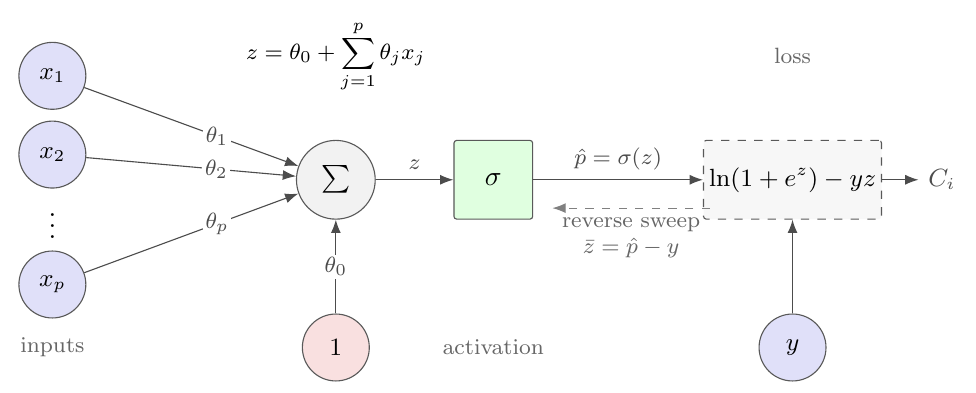

In [2]:
Image("../BookFigures/chapter05_logistic_regression/5-neuron.png", width=640)

Read as a *computational graph* — parameters as inputs, data as constants,
the loss as output (book Figure 5.5) — the same diagram is the evaluation
trace of Eq. (5.38), and reverse-mode automatic differentiation is the neuron
read backwards. Below: the trace for one observation, the reverse sweep of
Eq. (5.41) written out by hand, forward mode with `jax.jvp` (one sweep per
parameter) and reverse mode with `jax.grad` (one sweep for all), at
$\boldsymbol{\theta}=(0.5, 0.25)$, $x=2$, $y=1$.

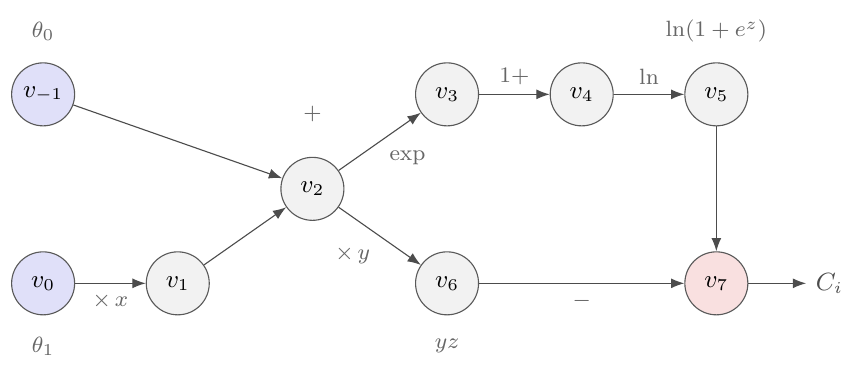

In [3]:
Image("../BookFigures/chapter05_logistic_regression/5-logreggraph.png", width=560)

In [4]:
def cross_entropy_one(theta0, theta1, x, y):
    """The trace of Eq. (5.38) for one observation, one line per node."""
    v1 = theta1 * x
    v2 = v1 + theta0
    v3 = jnp.exp(v2)
    v4 = 1.0 + v3
    v5 = jnp.log(v4)
    v6 = y * v2
    return v5 - v6

def reverse_sweep(theta0, theta1, x, y):
    """Eq. (5.41) by hand: forward evaluation onto the tape, then back."""
    v1 = theta1 * x; v2 = v1 + theta0; v3 = np.exp(v2); v4 = 1.0 + v3   # tape
    b7 = 1.0
    b5, b6 = b7, -b7
    b4 = b5 / v4
    b3 = b4
    b2 = b3 * v3 + b6 * y                  # fan-out: two successors, one sum
    b1 = b2
    return float(b2), float(b1 * x)        # dC/dtheta0, dC/dtheta1

x, y = 2.0, 1.0
theta_one = jnp.array([0.5, 0.25])
cost_one = lambda th: cross_entropy_one(th[0], th[1], x, y)
z = 0.5 + 0.25 * x
print(f"tape: z = {z}, v3 = {np.exp(z):.3f}, v4 = {1+np.exp(z):.3f}, v5 = {np.log(1+np.exp(z)):.3f}, "
      f"C_i = {float(cost_one(theta_one)):.3f}, p = {np.exp(z)/(1+np.exp(z)):.3f}")
for k in range(2):                         # forward mode: one sweep per parameter
    _, tangent = jax.jvp(cost_one, (theta_one,), (jnp.eye(2)[k],))
    print(f"forward sweep, seed e_{k}: dC/dtheta_{k} = {float(tangent):.6f}")
print("reverse sweep, jax.grad:", np.asarray(jax.grad(cost_one)(theta_one)))
print("reverse sweep, by hand: ", reverse_sweep(0.5, 0.25, x, y))

tape: z = 1.0, v3 = 2.718, v4 = 3.718, v5 = 1.313, C_i = 0.313, p = 0.731
forward sweep, seed e_0: dC/dtheta_0 = -0.268941
forward sweep, seed e_1: dC/dtheta_1 = -0.537883
reverse sweep, jax.grad: [-0.2689 -0.5379]
reverse sweep, by hand:  (-0.2689414213699952, -0.5378828427399904)


At $v_2=z$ the two branches contribute $p$ and $-y$: the residual
$\hat p - y$ appears as the adjoint of the pre-activation, $\bar z$, produced
mechanically by the fan-out rule; from there the sweep only multiplies by the
input on each edge. Keep the name — today $\bar z$ is called $\delta$.

On the whole data set the graph is $n$ copies hanging from the same $p$
parameter nodes. One reverse sweep returns
$\bar{\boldsymbol{\theta}}=\boldsymbol{X}^T(\boldsymbol{p}-\boldsymbol{y})$,
Eq. (5.42), at the cost of one forward evaluation plus one matrix–vector
product — the cheap gradient principle, Proposition 4.2 — while forward mode
needs $p$ sweeps. Here on random data with $n=5000$, timed for growing $p$
(the book's Section 5.8.2 listing; the numbers on the slide were measured on
another machine, the ratios are what matter):

In [5]:
import time

def cost_jax(theta, X, y):                 # Eq. (5.43)
    z = X @ theta
    return jnp.mean(jnp.logaddexp(0.0, z) - y * z)

rng = np.random.default_rng(2024)
n = 5000
for p in (20, 200, 1000):
    Xp = jnp.asarray(np.column_stack([np.ones(n), rng.normal(size=(n, p - 1))]))
    yp = jnp.asarray(rng.integers(0, 2, n).astype(float))
    th = jnp.zeros(p)
    value = jax.jit(cost_jax)
    reverse = jax.jit(jax.grad(cost_jax))          # one reverse sweep
    forward = jax.jit(jax.jacfwd(cost_jax))        # p forward sweeps
    for fn in (value, reverse, forward):           # compile before timing
        fn(th, Xp, yp).block_until_ready()
    g_hand = Xp.T @ (jax.nn.sigmoid(Xp @ th) - yp) / n          # Eq. (5.17) / n
    print(f"p = {p:4d}: max|reverse - hand| = {float(jnp.max(jnp.abs(reverse(th, Xp, yp) - g_hand))):.1e}", end="")
    for name, fn in (("value", value), ("reverse", reverse), ("forward", forward)):
        t0 = time.perf_counter()
        for _ in range(10):
            fn(th, Xp, yp).block_until_ready()
        print(f"   {name} {1e3 * (time.perf_counter() - t0) / 10:7.2f} ms", end="")
    print()

p =   20: max|reverse - hand| = 5.4e-17   value    0.15 ms   reverse    0.12 ms   forward    0.36 ms
p =  200: max|reverse - hand| = 5.6e-17   value    0.35 ms   reverse    0.49 ms   forward    3.25 ms
p = 1000: max|reverse - hand| = 8.0e-17   value    1.81 ms   reverse    2.72 ms   forward   58.71 ms


Reverse mode costs one to two evaluations of the cost whatever $p$; forward
mode grows with $p$. A cost has one output and $p$ inputs — training asks the
reverse-mode question. **Pause and think 1:** if the inputs $x_j$ were
themselves outputs of neurons, the sweep would not stop at $\bar z$ — it
would continue through the activation of each input neuron and along its
edges. That is backpropagation, and Part 3 does it by hand.

## Part 2: neural networks and deep learning (Sections 8.1–8.7)

An artificial neuron, Eq. (8.1), is $y=f\bigl(\sum_i w_ix_i+b\bigr)$: with
$f$ the identity it is linear regression, with $f=\sigma$ logistic
regression, with the step function Rosenblatt's perceptron. In a *network*
the inputs of one neuron are the outputs of the neurons in the layer before.

### Why one layer is not enough: XOR (Section 8.2)

A single neuron computes one straight line in the plane, and the XOR gate
cannot be separated by any line. Least squares on the four points finds that
the best *linear* function is the constant $1/2$; logistic regression scores
chance. Not a training failure: the model class contains no solution.

In [7]:
X_gates = np.array([[1, 0, 0], [1, 0, 1], [1, 1, 0], [1, 1, 1]], dtype=float)   # with intercept column
for name, y in [("XOR", [0, 1, 1, 0]), ("OR", [0, 1, 1, 1]), ("AND", [0, 0, 0, 1])]:
    y = np.array(y, dtype=float)
    theta = np.linalg.pinv(X_gates.T @ X_gates) @ X_gates.T @ y
    print(f"{name}: theta = {np.round(theta, 3)}, least-squares prediction = {np.round(X_gates @ theta, 3)}")

XOR: theta = [ 0.5  0.  -0. ], least-squares prediction = [0.5 0.5 0.5 0.5]
OR: theta = [0.25 0.5  0.5 ], least-squares prediction = [0.25 0.75 0.75 1.25]
AND: theta = [-0.25  0.5   0.5 ], least-squares prediction = [-0.25  0.25  0.25  0.75]


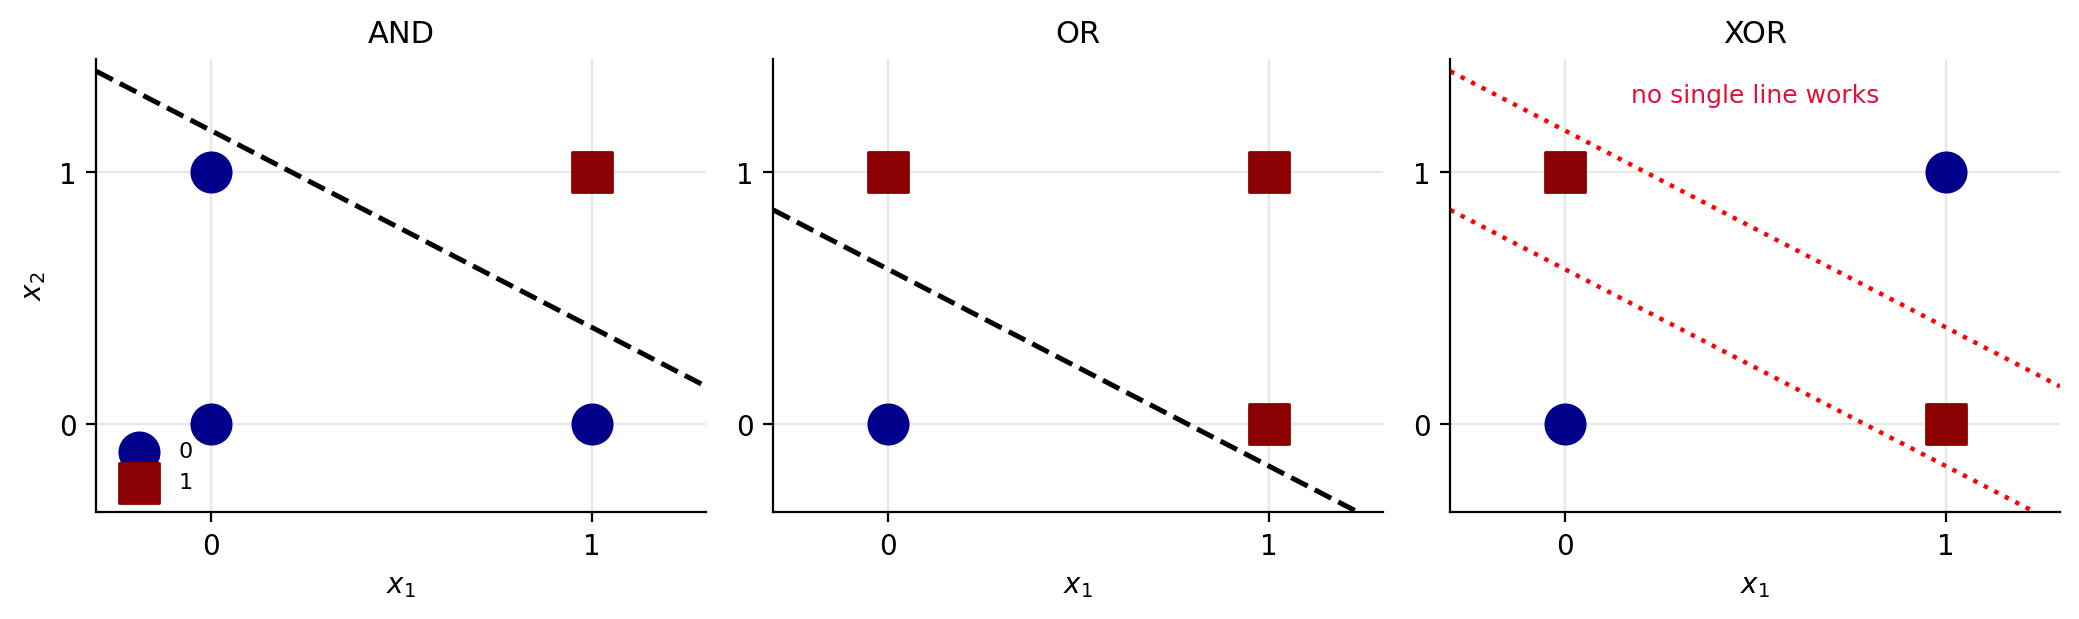

In [8]:
Image("../BookFigures/chapter08_neural_networks/xor_problem.png", width=760)

The remedy is a hidden layer. The 2–2–1 network derived in Part 3 (two
sigmoid hidden nodes, a sigmoid output, squared error, plain gradient descent)
learns XOR from the four points; the figure shows *what the hidden nodes
learned*: each is one neuron and draws one line, and in the plane of the two
hidden activations the four points are linearly separable, so the output
neuron can finish the job. A single neuron trained the same way returns $0.5$
four times.

In [9]:
def sigmoid(z):
    """The logistic function, Eq. (8.22)."""
    return 1.0 / (1.0 + np.exp(-z))


In [10]:
def forward(X, W1, b1, W2, b2, output="linear"):
    """Eqs. (8.44)-(8.46) for all samples at once (samples in rows, Eq. 8.21)."""
    Z1 = X @ W1 + b1; A1 = sigmoid(Z1)              # hidden layer
    Z2 = A1 @ W2 + b2                                # output pre-activation
    A2 = Z2 if output == "linear" else sigmoid(Z2)
    return A1, A2


In [11]:
def backward(X, y, W1, b1, W2, b2, output="linear"):
    """Eqs. (8.48), (8.54) and (8.55): the nine derivatives, mean over the sample."""
    n = X.shape[0]
    A1, A2 = forward(X, W1, b1, W2, b2, output)
    fprime = 1.0 if output == "linear" else A2 * (1 - A2)
    delta2 = (A2 - y) * fprime / n                   # output error, Eq. (8.48)
    delta1 = (delta2 @ W2.T) * A1 * (1 - A1)         # Eq. (8.54): (W2 delta2) o sigma'(z1)
    dW2 = A1.T @ delta2;  db2 = delta2.sum(axis=0)   # Eq. (8.53), l = 2
    dW1 = X.T @ delta1;   db1 = delta1.sum(axis=0)   # Eq. (8.55), summed over the sample
    return dW1, db1, dW2, db2, 0.5 * np.sum((A2 - y) ** 2) / n


In [12]:
def train_221(X, y, n_iter, gamma, seed=None, output="linear", n_hidden=2, every=1, rng=None):
    """Plain gradient descent on the 2-n_hidden-1 network; returns parameters and the cost history.

    The weights are drawn from `rng` if given (so that the book's numbers, where
    the data and the weights come from one generator, are reproduced), else
    from a fresh generator with the given seed.
    """
    rng = np.random.default_rng(seed) if rng is None else rng
    W1 = rng.standard_normal((2, n_hidden)); b1 = np.zeros(n_hidden) + 0.01
    W2 = rng.standard_normal((n_hidden, 1)); b2 = np.zeros(1) + 0.01
    hist = []
    for i in range(n_iter + 1):
        dW1, db1, dW2, db2, C = backward(X, y, W1, b1, W2, b2, output)
        if i % every == 0:
            hist.append(C)
        W1 -= gamma * dW1; b1 -= gamma * db1; W2 -= gamma * dW2; b2 -= gamma * db2
    return (W1, b1, W2, b2), np.array(hist)


In [13]:
XOR_X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
XOR_Y = np.array([[0], [1], [1], [0]], dtype=float)

def train_xor(n_iter=20000, gamma=2.0, seed=2026, every=100):
    """The 2-2-1 network with a sigmoid output on the XOR gate, squared error, plain gradient descent."""
    return train_221(XOR_X, XOR_Y, n_iter, gamma, seed, output="sigmoid", every=every)


def print_xor():
    params, hist = train_xor()
    W1, b1, W2, b2 = params
    A1, A2 = forward(XOR_X, W1, b1, W2, b2, output="sigmoid")
    print("XOR with two sigmoid hidden nodes, gamma = 2, seed 2026, 20000 iterations:")
    print("  cost after 0/1000/5000/20000 iterations:",
          " / ".join(f"{hist[k]:.4f}" for k in (0, 10, 50, -1)))
    print("  hidden activations at the four inputs:\n  ", A1.round(3).tolist())
    print("  outputs:", A2.ravel().round(3).tolist(), " -> predictions", (A2.ravel() > 0.5).astype(int).tolist())
    print("  W1 =", W1.round(2).tolist(), " b1 =", b1.round(2).tolist())
    print("  W2 =", W2.ravel().round(2).tolist(), " b2 =", b2.round(2).tolist())
    # a single neuron (no hidden layer) on the same data, for contrast
    rng = np.random.default_rng(2026)
    w = rng.standard_normal((2, 1)); b = np.zeros(1)
    for i in range(20000):
        p = sigmoid(XOR_X @ w + b)
        d = (p - XOR_Y) * p * (1 - p) / 4
        w -= 2.0 * XOR_X.T @ d; b -= 2.0 * d.sum(axis=0)
    print("  single neuron, same training:", sigmoid(XOR_X @ w + b).ravel().round(3).tolist(),
          "-> accuracy", np.mean((sigmoid(XOR_X @ w + b) > 0.5) == XOR_Y))


print_xor()

XOR with two sigmoid hidden nodes, gamma = 2, seed 2026, 20000 iterations:
  cost after 0/1000/5000/20000 iterations: 0.1284 / 0.0113 / 0.0004 / 0.0001
  hidden activations at the four inputs:
   [[0.934, 0.0], [0.018, 0.06], [0.019, 0.059], [0.0, 0.903]]
  outputs: [0.011, 0.988, 0.988, 0.012]  -> predictions [0, 1, 1, 0]
  W1 = [[-6.59, 4.99], [-6.64, 5.0]]  b1 = [2.66, -7.75]
  W2 = [-10.42, -10.71]  b2 = [5.22]
  single neuron, same training: [0.5, 0.5, 0.5, 0.5] -> accuracy 0.5


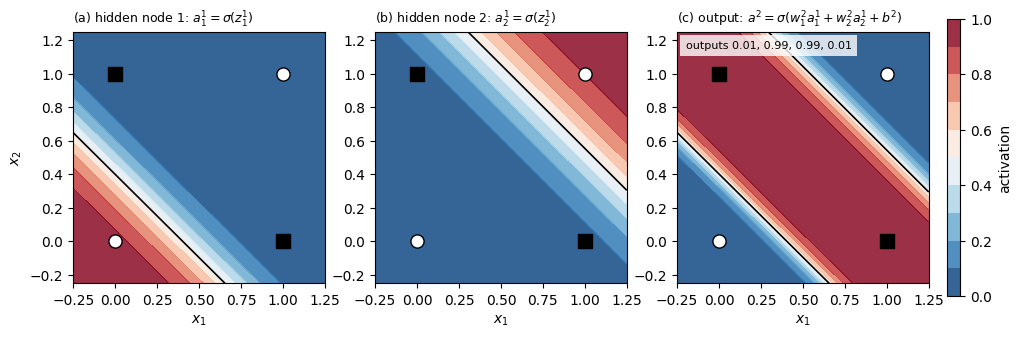

In [14]:
def figure_xor_hidden(fname="week40_xor_hidden.pdf"):
    params, hist = train_xor()
    W1, b1, W2, b2 = params
    g = np.linspace(-0.25, 1.25, 121); G1, G2 = np.meshgrid(g, g)
    grid = np.column_stack([G1.ravel(), G2.ravel()])
    A1, A2 = forward(grid, W1, b1, W2, b2, output="sigmoid")
    fields = [A1[:, 0], A1[:, 1], A2[:, 0]]
    titles = [r"hidden node 1: $a_1^1=\sigma(z_1^1)$", r"hidden node 2: $a_2^1=\sigma(z_2^1)$",
              r"output: $a^2=\sigma(w_1^2a_1^1+w_2^2a_2^1+b^2)$"]
    fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6))
    for ax, f, t in zip(axes, fields, titles):
        im = ax.contourf(G1, G2, f.reshape(G1.shape), levels=np.linspace(0, 1, 11), cmap="RdBu_r",
                         vmin=0, vmax=1, alpha=0.85)
        ax.contour(G1, G2, f.reshape(G1.shape), levels=[0.5], colors="k", linewidths=1.2)
        for (x1, x2), lab in zip(XOR_X, XOR_Y.ravel()):
            ax.scatter(x1, x2, s=90, marker="s" if lab else "o", color="k" if lab else "w",
                       edgecolor="k", zorder=5)
        ax.set_xlabel("$x_1$"); ax.set_aspect("equal")
    axes[0].set_ylabel("$x_2$")
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label="activation")
    _, out = forward(XOR_X, W1, b1, W2, b2, output="sigmoid")
    axes[2].text(-0.2, 1.15, "outputs " + ", ".join(f"{v:.2f}" for v in out.ravel()), fontsize=8,
                 bbox=dict(facecolor="w", edgecolor="none", alpha=0.8))
    for ax, lab, t in zip(axes, "abc", titles):
        ax.set_title(f"({lab}) " + t, loc="left", fontsize=9)
    fig.savefig(fname, bbox_inches="tight")
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150, bbox_inches="tight")
    return fig


figure_xor_hidden(); plt.show()

The two hidden nodes are "neither" and "both"; the output is "not neither
and not both" — XOR. **Non-linearity is essential**: with linear hidden
units $\boldsymbol{W}^2(\boldsymbol{W}^1\boldsymbol{x}+\boldsymbol{b}^1)+\boldsymbol{b}^2$
is again affine in $\boldsymbol{x}$, whatever the depth.

**Pause and think 2 (count the parameters).** A 784–100–100–10 network has
$784\cdot100+100+100\cdot100+100+100\cdot10+10 = 89\,610$ parameters. With
*linear* hidden layers it computes one affine map $\boldsymbol{x}\mapsto\boldsymbol{A}\boldsymbol{x}+\boldsymbol{c}$
with $\boldsymbol{A}$ of size $784\times10$: $7\,850$ numbers, and
multinomial logistic regression in disguise.

In [15]:
print("parameters:", 784*100 + 100 + 100*100 + 100 + 100*10 + 10)
rng = np.random.default_rng(1)
W1, W2, W3 = rng.normal(size=(784, 100)), rng.normal(size=(100, 100)), rng.normal(size=(100, 10))
A = W1 @ W2 @ W3
print("the linear network is one matrix of shape", A.shape, "with rank", np.linalg.matrix_rank(A),
      "-- at most", 784*10 + 10, "numbers matter")

parameters: 89610
the linear network is one matrix of shape (784, 10) with rank 10 -- at most 7850 numbers matter


### Notation, the feed-forward pass and the universal approximation theorem (Sections 8.4–8.5)

Layers $l=0,\dots,L$ with $M_l$ nodes; node $j$ of layer $l$ computes,
Eqs. (8.18)–(8.19),

$$
z_j^{l}=\sum_{i=1}^{M_{l-1}}w_{ij}^{l}a_i^{l-1}+b_j^{l},\qquad a_j^{l}=f\bigl(z_j^{l}\bigr),
$$

with $w_{ij}^l$ *leaving* node $i$ of layer $l-1$ and *arriving* at node $j$
of layer $l$; in the batch form of Eq. (8.21), samples in rows,
$\boldsymbol{Z}^l=\boldsymbol{A}^{l-1}\boldsymbol{W}^l+\boldsymbol{b}^l$ — the
form all code in this notebook uses.

The universal approximation theorem (Cybenko 1989, Hornik 1991; the sharp
condition of Leshno et al. 1993: the activation must not be a polynomial)
says that one hidden layer can approximate any continuous function on a
compact set to any accuracy. It says nothing about the width needed, the
size of the weights, or whether gradient descent finds them; the one-dimensional
constructive version, Theorem 8.2, gives $\sup|F-g|\le L(b-a)/2N$ for $N$
rectified units — the network *is* the piecewise-linear interpolant. The
cell below is that construction on $F(x)=\sin 2\pi x$.

In [16]:
def relu_interpolant(F, a, b, N):
    """Eq. (8.7): the piecewise-linear interpolant of F at N+1 knots as a one-hidden-layer ReLU network."""
    t = np.linspace(a, b, N + 1); h = (b - a) / N
    yk = F(t)
    s = np.diff(yk) / h                              # chord slopes
    v = np.concatenate([[s[0]], np.diff(s)])         # output weights s_k - s_{k-1}
    return lambda x: yk[0] + sum(v[k] * np.maximum(0.0, x - t[k]) for k in range(N))

F = lambda x: np.sin(2 * np.pi * x)
xx = np.linspace(0, 1, 2001)
L = 2 * np.pi                                        # Lipschitz constant of F on [0, 1]
for N in (4, 16, 64, 256):
    g = relu_interpolant(F, 0.0, 1.0, N)
    print(f"N = {N:3d} hidden ReLU units: sup|F - g| = {np.max(np.abs(F(xx) - g(xx))):.2e}   bound L/2N = {L/(2*N):.2e}")

N =   4 hidden ReLU units: sup|F - g| = 2.11e-01   bound L/2N = 7.85e-01
N =  16 hidden ReLU units: sup|F - g| = 1.88e-02   bound L/2N = 1.96e-01
N =  64 hidden ReLU units: sup|F - g| = 1.20e-03   bound L/2N = 4.91e-02
N = 256 hidden ReLU units: sup|F - g| = 7.52e-05   bound L/2N = 1.23e-02


### Activation functions (Section 8.6)

Only the *derivative* enters the backward pass. The sigmoid has
$\sigma'\le 1/4$ and dies in both tails; $\tanh'\le1$; ReLU has derivative
exactly $1$ or $0$; the smooth gated functions (GELU, Swish, Mish) have a
derivative slightly above one near the origin. **Pause and think 3:** ten
sigmoid layers attenuate a gradient by at least $(1/4)^{10}\approx10^{-6}$,
and by $10^{-22}$ if every pre-activation is $5$.

sigma'(0) = 0.25  sigma'(5) = 0.0066
ten layers at z = 0: 9.5e-07   ten layers at z = 5: 1.7e-22   ten ReLU layers (active): 1.0


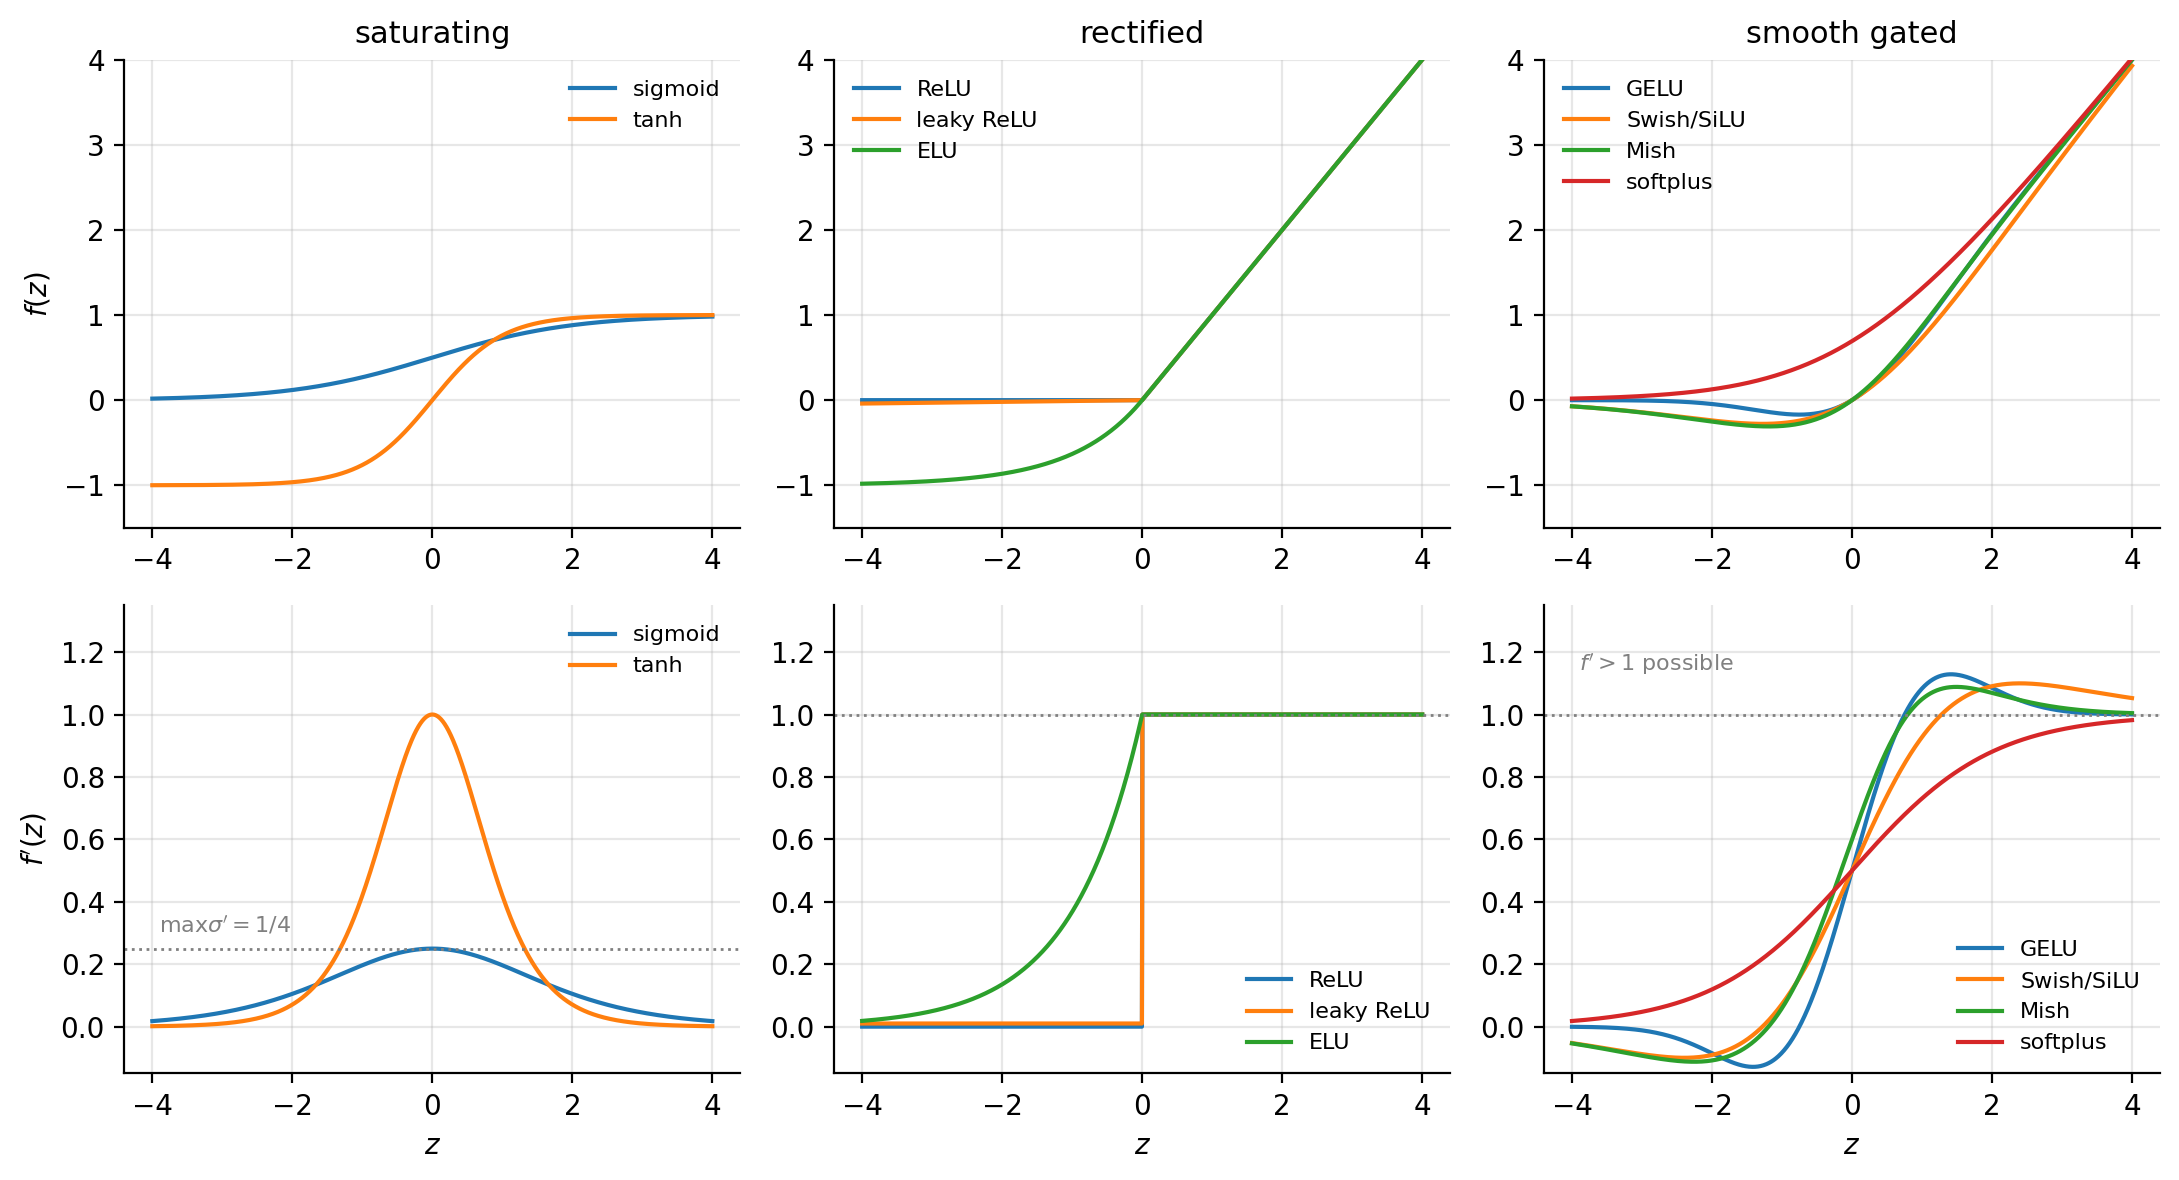

In [17]:
dsig = lambda z: 1/(1+np.exp(-z)) * (1 - 1/(1+np.exp(-z)))
print("sigma'(0) =", dsig(0.0), " sigma'(5) =", f"{dsig(5.0):.4f}")
print("ten layers at z = 0:", f"{dsig(0.0)**10:.1e}", "  ten layers at z = 5:", f"{dsig(5.0)**10:.1e}",
      "  ten ReLU layers (active):", 1.0**10)
Image("../BookFigures/chapter08_neural_networks/activation_families.png", width=820)

The cost we minimise, Eq. (8.31), is not convex, highly symmetric and has
very many parameters: first-order methods only, and an exact gradient for the
price of about two forward passes. That gradient is Part 3.

## Part 3: backpropagation from the smallest networks (Sections 8.8.1–8.8.2)

### No hidden layer, and one hidden layer, by hand

One node per layer, so only the layer superscript survives. For the single
neuron $x\to z^1=w^1x+b^1\to a^1=\sigma(z^1)\to C=\tfrac12(a^1-y)^2$ the
chain rule gives, Eqs. (8.34)–(8.36),

$$
\delta^1=(a^1-y)\,\sigma'(z^1)=\frac{\partial C}{\partial z^1},\qquad
\frac{\partial C}{\partial w^1}=\delta^1 x,\qquad
\frac{\partial C}{\partial b^1}=\delta^1 ,
$$

and $\delta^1$ is exactly the adjoint $\bar z$ of the reverse sweep, Eq. (8.39).
With a hidden neuron in front, Eq. (8.40), the output layer is the same
formula with $a^1$ in place of $x$, and the hidden weight's five-factor chain
collapses to the recursion of Eq. (8.43),

$$
\delta^1=\delta^2\,w^2\,\sigma'(z^1),\qquad
\frac{\partial C}{\partial w^1}=\delta^1 x,\qquad
\frac{\partial C}{\partial b^1}=\delta^1 .
$$

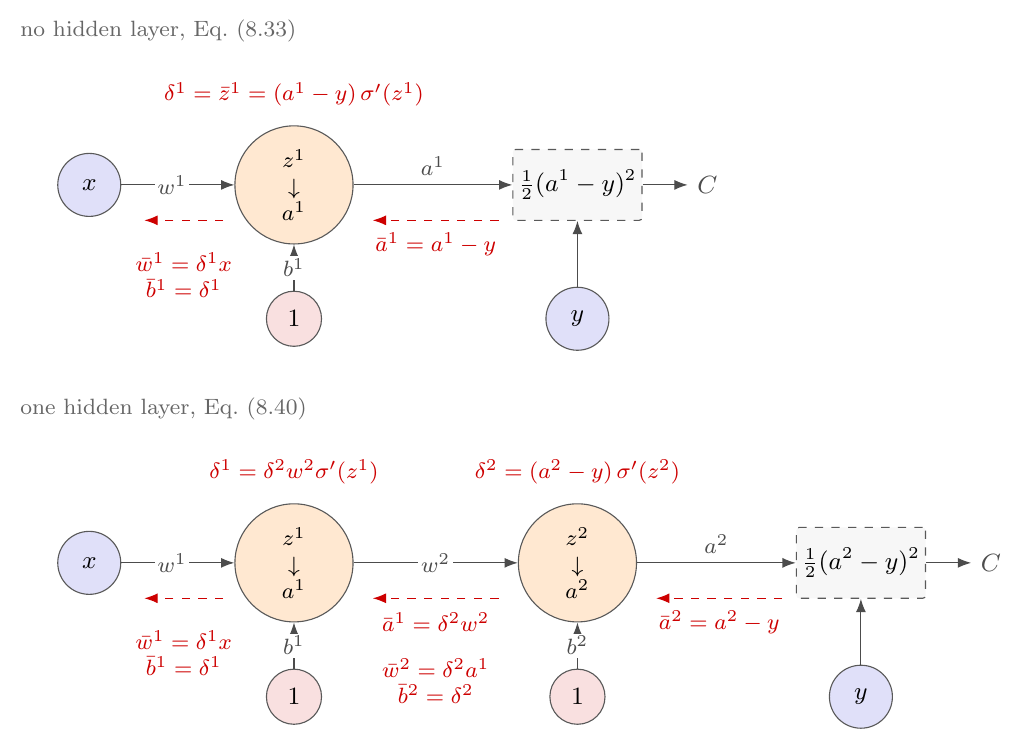

In [18]:
Image("../BookFigures/chapter08_neural_networks/8-scalargraph.png", width=700)

In [19]:
def grad_one(w1, b1, x, y):
    """No hidden layer, Eqs. (8.33)-(8.36): returns C, dC/dw1, dC/db1, delta1."""
    z1 = w1 * x + b1
    a1 = sigmoid(z1)                                 # forward pass, store z1, a1
    delta1 = (a1 - y) * a1 * (1.0 - a1)              # Eq. (8.35): (a1 - y) sigma'(z1)
    return 0.5 * (a1 - y) ** 2, delta1 * x, delta1, delta1


def grad_two(w1, b1, w2, b2, x, y):
    """One hidden layer, Eqs. (8.40)-(8.43): returns C and the four gradients, then delta1, delta2."""
    z1 = w1 * x + b1
    a1 = sigmoid(z1)                                 # forward pass
    z2 = w2 * a1 + b2
    a2 = sigmoid(z2)
    delta2 = (a2 - y) * a2 * (1.0 - a2)              # output error, Eq. (8.41)
    delta1 = delta2 * w2 * a1 * (1.0 - a1)           # Eq. (8.43): delta2 w2 sigma'(z1)
    return (0.5 * (a2 - y) ** 2, delta1 * x, delta1, delta2 * a1, delta2, delta1, delta2)


x, y = 2.0, 1.0
C1, gw1, gb1, d1 = grad_one(0.25, 0.5, x, y)
print(f"no hidden layer : C = {C1:.4f}  delta1 = {d1:.4f}   dC/dw1 = {gw1:.4f}  dC/db1 = {gb1:.4f}")
C2, gw1, gb1, gw2, gb2, d1, d2 = grad_two(0.25, 0.5, 1.0, -0.5, x, y)
print(f"one hidden layer: C = {C2:.4f}  delta2 = {d2:.4f}  delta1 = {d1:.4f}")
print(f"   dC/dw1 = {gw1:.4f}  dC/db1 = {gb1:.4f}  dC/dw2 = {gw2:.4f}  dC/db2 = {gb2:.4f}")
print("cross-entropy gradient at the same point (Part 1): (-0.538, -0.269); ratio = sigma'(1) =", f"{0.1058/0.538:.3f}")

no hidden layer : C = 0.0362  delta1 = -0.0529   dC/dw1 = -0.1058  dC/db1 = -0.0529
one hidden layer: C = 0.0979  delta2 = -0.1092  delta1 = -0.0215
   dC/dw1 = -0.0429  dC/db1 = -0.0215  dC/dw2 = -0.0798  dC/db2 = -0.1092
cross-entropy gradient at the same point (Part 1): (-0.538, -0.269); ratio = sigma'(1) = 0.197


The squared-error gradient of the single neuron is the cross-entropy
gradient of Part 1 times $\sigma'(z^1)=0.197$: with the squared error nothing
cancels the derivative of the sigmoid, and a saturated neuron learns slowly
however wrong it is.

### The same by automatic differentiation

`jax.grad` of the *forward pass only* reproduces every digit; `jax.jvp` with
the two unit seeds returns the same numbers one at a time.

In [20]:
def C_one(p, x, y):                    # forward pass of the single neuron ...
    return 0.5*(jax.nn.sigmoid(p[0]*x + p[1]) - y)**2
def C_two(p, x, y):                    # ... and with the hidden neuron
    a1 = jax.nn.sigmoid(p[0]*x + p[1])
    return 0.5*(jax.nn.sigmoid(p[2]*a1 + p[3]) - y)**2

p1, p2 = jnp.array([0.25, 0.5]), jnp.array([0.25, 0.5, 1.0, -0.5])
print("no hidden layer,  jax.grad:", jax.grad(C_one)(p1, x, y))
print("one hidden layer, jax.grad:", jax.grad(C_two)(p2, x, y))
print("no hidden layer,  jax.jvp: ", [float(jax.jvp(C_one, (p1, x, y), (s, 0.0, 0.0))[1]) for s in jnp.eye(2)])

no hidden layer,  jax.grad: [-0.1058 -0.0529]
one hidden layer, jax.grad: [-0.0429 -0.0215 -0.0798 -0.1092]
no hidden layer,  jax.jvp:  [-0.10575418556853343, -0.052877092784266715]


### A first training program — and the learning rate

The same equations with arrays (samples in rows, weights of shape (inputs,
outputs), linear output so that $\delta^2=a^2-y$): make the network return
$y=2x+1=9$ at $x=4$ from random weights, seed 0. At $\gamma=0.1$ the cost
falls by nine orders of magnitude in fifty iterations. At $\gamma=1$ the first
steps drive the hidden weight to $w^1\approx4$, $z^1\approx16$,
$\sigma'(z^1)\approx10^{-7}$: every gradient reaching the first layer is
multiplied by that factor, the hidden neuron stops learning and the cost
stalls at $5.02$.

In [21]:
def train_scalar(gamma, n_iter=50, seed=0):
    """One input, one hidden sigmoid node, one linear output; x = 4, y = 2x + 1.

    Returns the cost, the hidden pre-activation z^1 and sigma'(z^1) after every
    iteration.  With seed 0 and gamma = 0.1 this is the program of the book:
    cost 36.9 -> 3e-7 in fifty iterations.
    """
    rng = np.random.RandomState(seed)
    x = np.array([[4.0]])
    y = 2 * x + 1.0
    w_1 = rng.randn(1, 1); b_1 = np.zeros(1) + 0.01
    w_2 = rng.randn(1, 1); b_2 = np.zeros(1) + 0.01
    cost, zhist, dhist = [], [], []
    for i in range(n_iter):
        z_1 = x @ w_1 + b_1
        a_1 = sigmoid(z_1)
        a_2 = a_1 @ w_2 + b_2                        # linear output
        delta_2 = a_2 - y                            # f' = 1 at the output
        delta_1 = (delta_2 @ w_2.T) * a_1 * (1 - a_1)  # Eq. (8.43) in array form
        cost.append(0.5 * np.sum((a_2 - y) ** 2))
        zhist.append(z_1.item()); dhist.append((a_1 * (1 - a_1)).item())
        w_2 -= gamma * (a_1.T @ delta_2); b_2 -= gamma * delta_2.sum(axis=0)
        w_1 -= gamma * (x.T @ delta_1);   b_1 -= gamma * delta_1.sum(axis=0)
    return np.array(cost), np.array(zhist), np.array(dhist)


def print_scalar_saturation():
    for g in (0.1, 1.0):
        c, z, d = train_scalar(g)
        print(f"gamma = {g}: cost after 0/10/20/49 iterations = "
              f"{c[0]:.3f} / {c[10]:.3e} / {c[20]:.3e} / {c[-1]:.3e};  "
              f"z^1 at the end = {z[-1]:.2f}, sigma'(z^1) = {d[-1]:.2e}")


print_scalar_saturation()

gamma = 0.1: cost after 0/10/20/49 iterations = 36.896 / 4.270e-01 / 4.939e-03 / 1.194e-08;  z^1 at the end = 7.20, sigma'(z^1) = 7.45e-04
gamma = 1.0: cost after 0/10/20/49 iterations = 36.896 / 5.022e+00 / 5.022e+00 / 5.022e+00;  z^1 at the end = 15.97, sigma'(z^1) = 1.16e-07


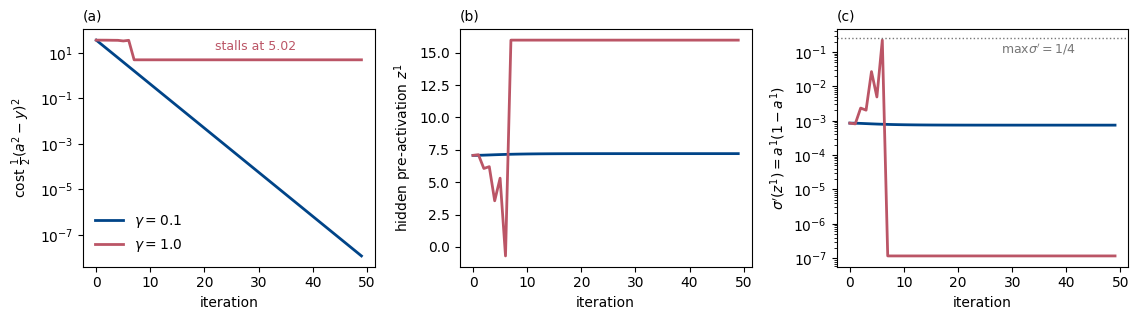

In [22]:
def figure_scalar_saturation(fname="week40_scalar_saturation.pdf"):
    runs = {0.1: train_scalar(0.1), 1.0: train_scalar(1.0)}
    fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.3))
    for (g, (c, z, d)), col in zip(runs.items(), (BLUE, RED)):
        it = np.arange(len(c))
        axes[0].semilogy(it, np.maximum(c, 1e-9), color=col, lw=2, label=rf"$\gamma={g}$")
        axes[1].plot(it, z, color=col, lw=2)
        axes[2].semilogy(it, d, color=col, lw=2)
    axes[0].set_ylabel(r"cost $\frac{1}{2}(a^2-y)^2$"); axes[0].legend(frameon=False)
    axes[1].set_ylabel(r"hidden pre-activation $z^1$")
    axes[2].set_ylabel(r"$\sigma'(z^1)=a^1(1-a^1)$")
    axes[2].axhline(0.25, color=GREY, ls=":", lw=1)
    axes[2].text(28, 0.09, r"$\max\sigma'=1/4$", color=GREY, fontsize=9)
    axes[0].text(22, 14, "stalls at 5.02", color=RED, fontsize=9)
    for ax, lab in zip(axes, "abc"):
        ax.set_xlabel("iteration")
        ax.set_title(f"({lab})", loc="left", fontsize=10)
    fig.tight_layout()
    fig.savefig(fname, bbox_inches="tight")
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150, bbox_inches="tight")
    return fig


figure_scalar_saturation(); plt.show()

**Pause and think 4 (who did the learning?).** In the successful run the
hidden weight barely moved ($1.764\to1.796$) and $\sigma'(z^1)\approx7\times10^{-4}$
throughout: the *output* layer, which is linear in $(w^2,b^2)$, did the
fitting, and a single target can always be hit that way. The cell below
checks it, and then trains the same program with `jax.grad` in place of the
hand-written backward pass — identical costs and parameters to all digits.

In [23]:
np.random.seed(0)
w10, w20 = np.random.randn(1, 1), np.random.randn(1, 1)
print("initial w_1 =", w10.ravel(), " w_2 =", w20.ravel())

def cost(params, x, y):
    w_1, b_1, w_2, b_2 = params
    a_1 = jax.nn.sigmoid(x @ w_1 + b_1)        # the forward pass, nothing else
    a_2 = a_1 @ w_2 + b_2
    return 0.5*jnp.sum((a_2 - y)**2)

grad = jax.jit(jax.grad(cost))                 # the backward pass, generated
xj = jnp.array([[4.0]]); yj = 2*xj + 1.0
params = [jnp.array(w10), jnp.zeros(1) + 0.01, jnp.array(w20), jnp.zeros(1) + 0.01]
gamma = 0.1
for i in range(50):
    if i % 10 == 0 or i == 49:
        print(f"iteration {i:2d}: cost = {cost(params, xj, yj):.6f}")
    g = grad(params, xj, yj)
    params = [p - gamma*gp for p, gp in zip(params, g)]
w_1, b_1, w_2, b_2 = params
print("w_1 =", np.asarray(w_1).ravel(), " b_1 =", np.asarray(b_1), " w_2 =", np.asarray(w_2).ravel(), " b_2 =", np.asarray(b_2))
print("hidden activation at x = 4:", float(jax.nn.sigmoid(xj @ w_1 + b_1)[0, 0]), " -> the output layer is a line through one point")

initial w_1 = [1.7641]  w_2 = [0.4002]
iteration  0: cost = 36.895631
iteration 10: cost = 0.426990
iteration 20: cost = 0.004939
iteration 30: cost = 0.000057
iteration 40: cost = 0.000001
iteration 49: cost = 0.000000
w_1 = [1.7958]  b_1 = [0.0179]  w_2 = [4.695]  b_2 = [4.3084]
hidden activation at x = 4: 0.9992548518697457  -> the output layer is a line through one point


Both networks trained on twenty noisy points, book Figure 8.11: the deeper
network reaches a *higher* cost in the same number of steps, because the
gradient that trains its hidden neuron carries the extra factor
$w^2\sigma'(z^2)\approx0.25$ of Eq. (8.43).

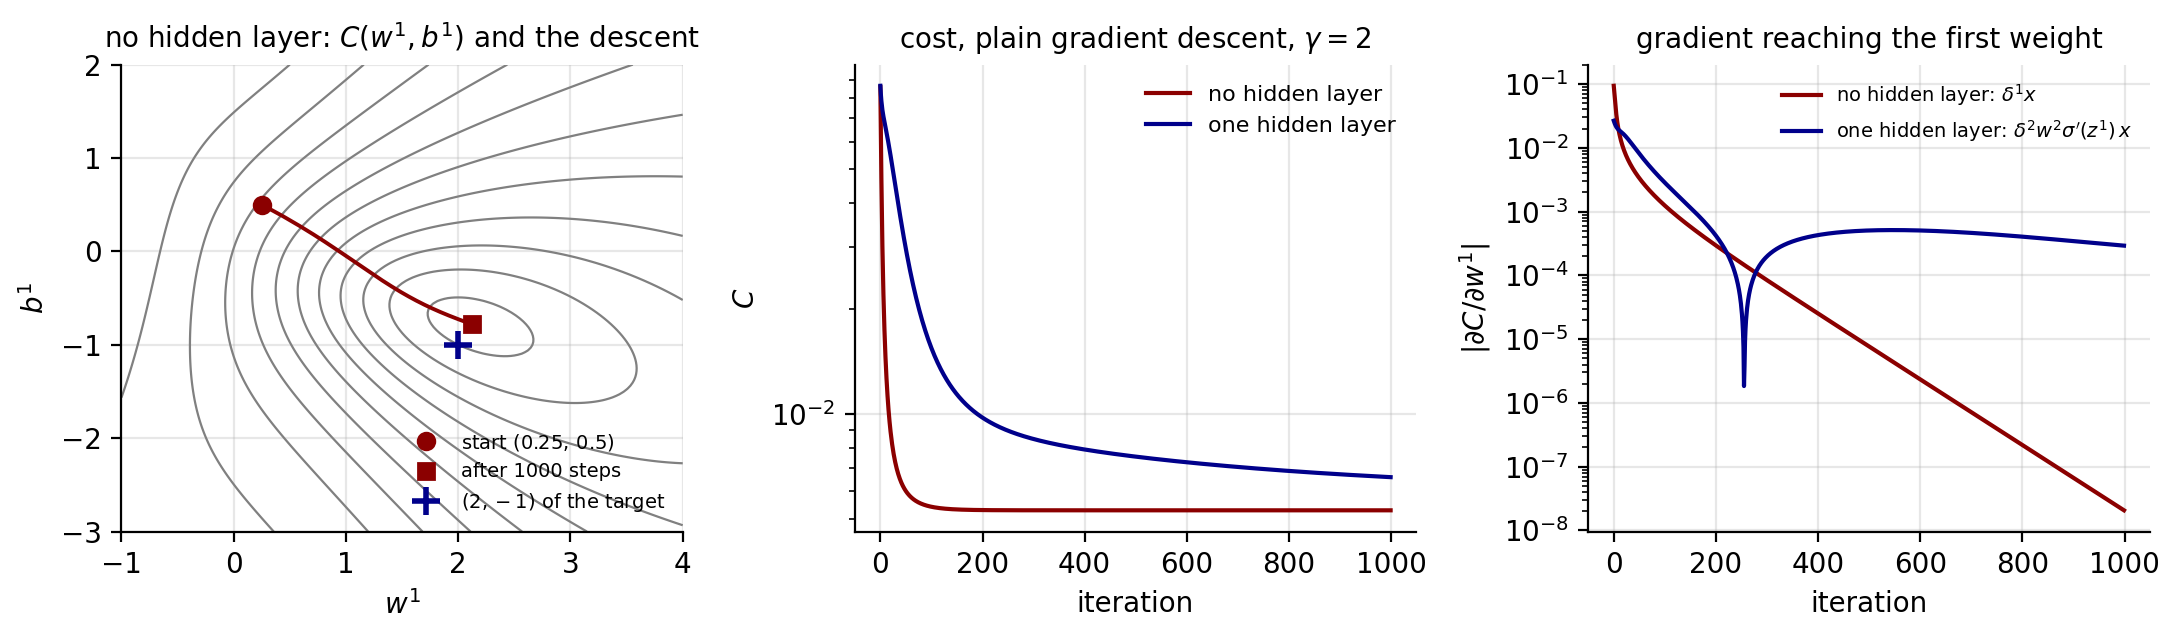

In [24]:
Image("../BookFigures/chapter08_neural_networks/scalar_backprop.png", width=900)

### Two inputs, two hidden nodes, one output (Section 8.8.2)

The smallest network in which a weight needs two indices: $w_{ij}^1$ leaves
input $i$ and arrives at hidden node $j$, Eqs. (8.44)–(8.47). The nine
derivatives, Eqs. (8.48)–(8.52), collapse to one rule with indices,
Eq. (8.53),

$$
\frac{\partial C}{\partial w_{ij}^{l}}=\delta_j^{l}\,a_i^{l-1},\qquad
\frac{\partial C}{\partial b_j^{l}}=\delta_j^{l},\qquad
\delta_j^{1}=\delta^{2}\,w_j^{2}\,\sigma'(z_j^{1}),
$$

in vector form $\boldsymbol{\delta}^1=(\boldsymbol{W}^2\delta^2)\circ\sigma'(\boldsymbol{z}^1)$
and $\partial C/\partial\boldsymbol{W}^1=\boldsymbol{x}(\boldsymbol{\delta}^1)^T$,
Eqs. (8.54)–(8.55). The functions `forward`, `backward` and `train_221`
defined for XOR above are exactly these equations for all samples at once,
with `X.T @ delta1` summing the outer products. Here on the book's regression
target $y=x_1^2+3x_1x_2+x_2^2+5$, $n=100$, seed 41, $\gamma=0.5$, with the
nine hand-derived derivatives checked against `jax.grad` first.

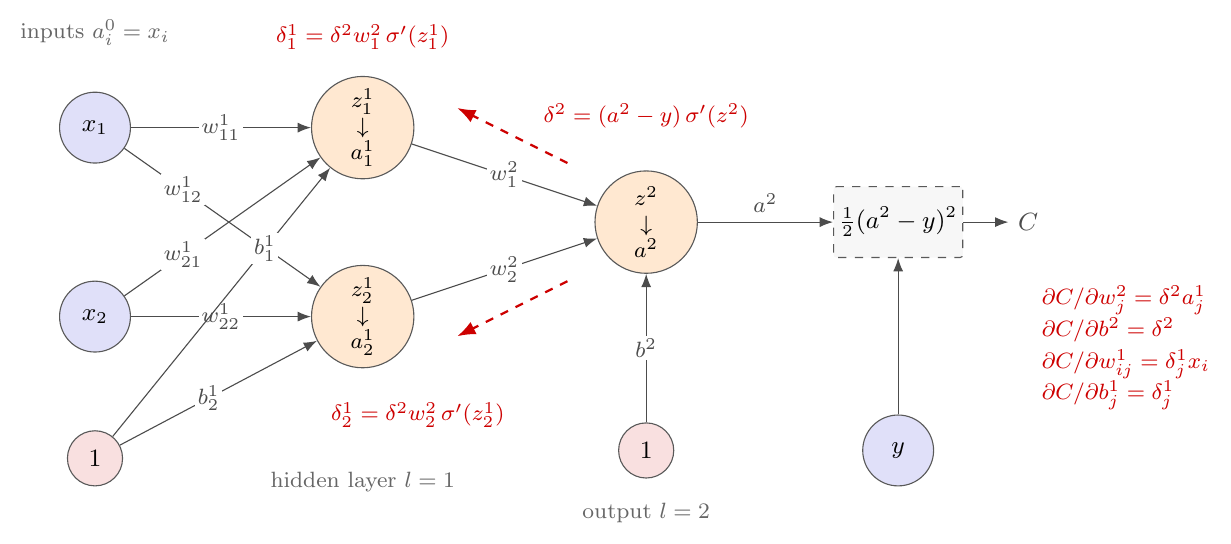

In [25]:
Image("../BookFigures/chapter08_neural_networks/8-twotwo.png", width=760)

In [26]:
def quadratic_data(n=100, seed=41):
    """The regression target of Section 8.8.2: y = x1^2 + 3 x1 x2 + x2^2 + 5 on the unit square.

    Returns X, y and the generator, which the book then uses for the initial weights.
    """
    rng = np.random.default_rng(seed)
    X = rng.uniform(0, 1, size=(n, 2))
    y = (X[:, 0] ** 2 + 3 * X[:, 0] * X[:, 1] + X[:, 1] ** 2 + 5).reshape(-1, 1)
    return X, y, rng


def print_twotwo():
    X, y, rng = quadratic_data()
    params, hist = train_221(X, y, n_iter=5000, gamma=0.5, rng=rng, every=1000)
    W1, b1, W2, b2 = params
    print("2-2-1 on y = x1^2 + 3 x1 x2 + x2^2 + 5, gamma = 0.5, seed 41:")
    for k, C in enumerate(hist):
        print(f"  iteration {1000 * k:4d}: cost = {C:.5f}")
    _, A2 = forward(X, W1, b1, W2, b2)
    print(f"  rms error {np.sqrt(np.mean((A2 - y) ** 2)):.4f} on targets in [5, 10]")
    print("  W1 =", W1.round(3).tolist(), " b1 =", b1.round(3).tolist())
    print("  W2 =", W2.ravel().round(3).tolist(), " b2 =", b2.round(3).tolist())
    # hand-derived gradient against reverse-mode automatic differentiation
    try:
        import jax, jax.numpy as jnp
        jax.config.update("jax_enable_x64", True)

        def cost(params, X, y):
            W1, b1, W2, b2 = params
            A1 = jax.nn.sigmoid(X @ W1 + b1)
            return 0.5 * jnp.mean((A1 @ W2 + b2 - y) ** 2)
        X, y, rng = quadratic_data()                # the same generator state as the book
        W1 = rng.standard_normal((2, 2)); b1 = np.zeros(2) + 0.01
        W2 = rng.standard_normal((2, 1)); b2 = np.zeros(1) + 0.01
        g_hand = backward(X, y, W1, b1, W2, b2)[:4]
        g_jax = jax.grad(cost)([jnp.array(p) for p in (W1, b1, W2, b2)], X, y)
        print("  max |hand - jax.grad| over the nine derivatives:",
              max(float(jnp.max(jnp.abs(h - j))) for h, j in zip(g_hand, g_jax)))
    except ImportError:
        print("  (jax not installed: the hand/AD comparison was skipped)")


print_twotwo()

2-2-1 on y = x1^2 + 3 x1 x2 + x2^2 + 5, gamma = 0.5, seed 41:
  iteration    0: cost = 22.76355
  iteration 1000: cost = 0.00113
  iteration 2000: cost = 0.00082
  iteration 3000: cost = 0.00082
  iteration 4000: cost = 0.00082
  iteration 5000: cost = 0.00081
  rms error 0.0404 on targets in [5, 10]
  W1 = [[2.524, 1.048], [2.558, 1.052]]  b1 = [-4.123, -1.965]
  W2 = [5.084, 2.981]  b2 = [4.454]
  max |hand - jax.grad| over the nine derivatives: 1.7763568394002505e-15


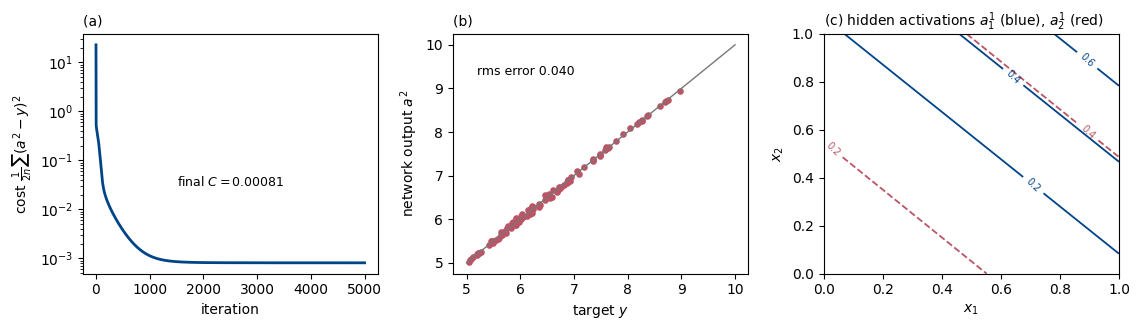

In [27]:
def figure_twotwo(fname="week40_twotwo.pdf"):
    X, y, rng = quadratic_data()
    params, hist = train_221(X, y, n_iter=5000, gamma=0.5, rng=rng)
    W1, b1, W2, b2 = params
    fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4))
    axes[0].semilogy(hist, color=BLUE, lw=2)
    axes[0].set_xlabel("iteration"); axes[0].set_ylabel(r"cost $\frac{1}{2n}\sum(a^2-y)^2$")
    axes[0].text(1500, 3e-2, f"final $C={hist[-1]:.5f}$", fontsize=9)
    _, A2 = forward(X, W1, b1, W2, b2)
    axes[1].plot([5, 10], [5, 10], color=GREY, lw=1)
    axes[1].scatter(y, A2, s=14, color=RED)
    axes[1].set_xlabel("target $y$"); axes[1].set_ylabel("network output $a^2$")
    rms = np.sqrt(np.mean((A2 - y) ** 2))
    axes[1].text(5.2, 9.3, f"rms error {rms:.3f}", fontsize=9)
    g = np.linspace(0, 1, 101); G1, G2 = np.meshgrid(g, g)
    grid = np.column_stack([G1.ravel(), G2.ravel()])
    A1, _ = forward(grid, W1, b1, W2, b2)
    for j, ls in zip(range(2), ("-", "--")):
        cs = axes[2].contour(G1, G2, A1[:, j].reshape(G1.shape), levels=[0.2, 0.4, 0.6, 0.8],
                             colors=[BLUE, RED][j], linestyles=ls, linewidths=1.3)
        axes[2].clabel(cs, fmt="%.1f", fontsize=7)
    axes[2].set_xlabel("$x_1$"); axes[2].set_ylabel("$x_2$")
    titles = ["", "", r"hidden activations $a_1^1$ (blue), $a_2^1$ (red)"]
    for ax, lab, t in zip(axes, "abc", titles):
        ax.set_title(f"({lab}) " + t, loc="left", fontsize=10)
    fig.tight_layout()
    fig.savefig(fname, bbox_inches="tight")
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150, bbox_inches="tight")
    return fig


figure_twotwo(); plt.show()

Two hidden nodes are two sigmoid ridges across the unit square, and the
linear output node combines them into a surface that follows the quadratic
target to $0.4\%$ — no polynomial features chosen by us.

**Pause and think 5 (a second output node).** Give the network two output
nodes. Then $z_j^1$ reaches the cost along *two* paths and the hidden error
acquires a sum, $\delta_j^1=\bigl(\sum_k\delta_k^2w_{jk}^2\bigr)\sigma'(z_j^1)$
— the fan-out rule of Section 4.14.4, and Eq. (8.66) of next week in full
generality. The cell checks the formula against `jax.grad` on a 2–2–2 network
with squared-error cost.

In [28]:
def backward_222(X, y, W1, b1, W2, b2):
    """The 2-2-2 network with sigmoid output: Eq. (8.66) with a 2x2 W2, i.e. the fan-out sum."""
    n = X.shape[0]
    A1 = sigmoid(X @ W1 + b1); A2 = sigmoid(A1 @ W2 + b2)
    delta2 = (A2 - y) * A2 * (1 - A2) / n            # one error per output node, Eq. (8.65)
    delta1 = (delta2 @ W2.T) * A1 * (1 - A1)         # sum_k delta_k^2 w_jk^2, then o sigma'(z1)
    return X.T @ delta1, delta1.sum(axis=0), A1.T @ delta2, delta2.sum(axis=0)

def cost_222(params, X, y):
    W1, b1, W2, b2 = params
    A2 = jax.nn.sigmoid(jax.nn.sigmoid(X @ W1 + b1) @ W2 + b2)
    return 0.5 * jnp.mean(jnp.sum((A2 - y)**2, axis=1))

rng = np.random.default_rng(3)
X2 = rng.uniform(-1, 1, size=(50, 2)); Y2 = rng.uniform(0, 1, size=(50, 2))
W1 = rng.standard_normal((2, 2)); b1 = np.zeros(2) + 0.01
W2 = rng.standard_normal((2, 2)); b2 = np.zeros(2) + 0.01
g_hand = backward_222(X2, Y2, W1, b1, W2, b2)
g_jax = jax.grad(cost_222)([jnp.array(p) for p in (W1, b1, W2, b2)], X2, Y2)
print("2-2-2 network, max |hand - jax.grad| over all twelve derivatives:",
      max(float(jnp.max(jnp.abs(h - j))) for h, j in zip(g_hand, g_jax)))

2-2-2 network, max |hand - jax.grad| over all twelve derivatives: 6.938893903907228e-18


## Summary

* **The reminder:** logistic regression is one neuron; its learning rule is
  error times the input on the edge; one reverse sweep gives the whole
  gradient for two evaluations of the cost, forward mode needs $p$ sweeps.
* **Networks:** one layer draws one line and cannot do XOR; a hidden layer
  learns the features that make the problem linear; the activation must be
  non-linear (not a polynomial) for universality, which says nothing about
  width or learnability; only $f'$ enters the backward pass.
* **Backpropagation from the smallest networks:** the error
  $\delta=\partial C/\partial z$ is the adjoint of the pre-activation, a
  weight's gradient is $\delta$ times its input,
  $\delta^1=\delta^2w^2\sigma'(z^1)$ with one hidden layer,
  $\partial C/\partial w_{ij}^l=\delta_j^la_i^{l-1}$ with indices; `jax.grad`
  of the forward pass reproduces every digit; a saturated hidden neuron
  stops learning.
* **Next week:** the sum over receiving nodes, the four equations
  (8.65)–(8.68), the algorithm, and your own network class (Section 8.13).

Tuesday is devoted to Project 1 (`week40tuesday.ipynb`); no weekly
exercises; **Project 1 is due Monday October 5**.